# 14 · When is the participant asleep?

**Hands-on time: 15 minutes** · Beginner Python · Teaching order: **14 → 01 → 05**

[14](01_YASA_automatic_sleep_staging.ipynb) · [01](02_YASA_spindles_detection.ipynb) · [05](03_YASA_sw_detection.ipynb)

## What you will learn

* Read a reference and a predicted hypnogram.
* Interpret predicted probabilities and flag epochs for review.
* Inspect EEG, EOG and EMG before accepting a label.

Work with a neighbour: make a prediction before running each experiment, then
point to the plot or table that supports your interpretation. Use **Shift+Enter**
to run one cell. The examples and exercises are adapted from the corresponding
[YASA source notebook](https://github.com/raphaelvallat/yasa/blob/master/notebooks/14_automatic_sleep_staging.ipynb).

## Before the timed lesson

Run the next two setup cells and the data-loading cell before class. In VS Code,
choose **.venv-yasa**. In Colab, upload this notebook, use a fresh CPU runtime
and run setup first; restart once if installation requests it. Local execution is
tested; rehearse in the actual Colab interface before teaching there.

In [1]:
import importlib.util
import subprocess
import sys

try:
    import google.colab
    IN_COLAB = True
except ModuleNotFoundError:
    IN_COLAB = False

if IN_COLAB:
    subprocess.check_call([
        sys.executable, "-m", "pip", "install", "-q",
        "yasa==0.8.1", "ipywidgets>=8,<9",
    ])
    from google.colab import output
    output.enable_custom_widget_manager()
else:
    print("Local mode: select .venv-yasa as the notebook kernel.")

Local mode: select workshop/.venv as the notebook kernel.


In [2]:
import ctypes
import importlib.metadata as metadata
import json
import os
from pathlib import Path

# Find the existing workshop from either its folder or a notebook subfolder.
if IN_COLAB:
    ROOT = Path.cwd() / "yasa_sleep_workshop"
else:
    candidates = [Path.cwd(), *Path.cwd().parents]
    ROOT = next((p for p in candidates if (p / "requirements.txt").is_file()
                 and (p / "YASA_LICENSE.txt").is_file()), None)
    if ROOT is None:
        project = next((p for p in candidates if (p / "workshop" / "requirements.txt").is_file()), None)
        if project is None:
            raise RuntimeError("Open the repository root in VS Code and select .venv-yasa.")
        ROOT = project / "workshop"
ROOT.mkdir(parents=True, exist_ok=True)
for variable, folder in {"YASA_DATA_DIR": "data", "MPLCONFIGDIR": ".mplconfig", "NUMBA_CACHE_DIR": ".numba-cache"}.items():
    (ROOT / folder).mkdir(exist_ok=True)
    os.environ.setdefault(variable, str(ROOT / folder))

omp = ROOT / ".runtime" / "lib" / "libomp.dylib"
if sys.platform == "darwin" and omp.is_file():
    ctypes.CDLL(str(omp), mode=ctypes.RTLD_GLOBAL)

import ipywidgets as widgets
import matplotlib.pyplot as plt
import mne
import numpy as np
import pandas as pd
import yasa
from IPython.display import display
from mne.filter import filter_data

plt.rcParams.update({"figure.figsize": (11, 3), "figure.dpi": 110, "font.size": 11,
                     "axes.spines.top": False, "axes.spines.right": False})
mne.set_log_level("ERROR")
assert yasa.__version__ == "0.8.1", "Select the prepared YASA 0.8.1 workshop environment."
OUT = ROOT / "outputs" / "three_notebook_workshop" / "14_automatic_sleep_staging"
OUT.mkdir(parents=True, exist_ok=True)
versions = {name: metadata.version(name) for name in ["yasa", "mne", "numpy", "pandas", "scipy", "ipywidgets"]}
(OUT / "versions.json").write_text(json.dumps(versions, indent=2))
print("Python:", sys.executable)
print("YASA:", yasa.__version__, "| Results:", OUT)

Python: <repository>/.venv/bin/python
YASA: 0.8.1 | Results: <repository>/outputs/three_notebook_workshop/14_automatic_sleep_staging


## 1. Meet the recording

This is the **49-minute nap** used in YASA notebook 14: six EEG channels,
two EOG channels and one chin-EMG channel, sampled at 100 Hz. The reference
assigns one stage to each 30-second epoch. MNE stores voltages in **volts**;
plots below request **microvolts (µV)** explicitly.

**Predict:** will every epoch be equally easy to classify? What evidence
might help distinguish quiet wakefulness, light sleep and REM?

In [3]:
raw_path = yasa.fetch_sample("sub-02_mne_raw.fif")
reference_path = yasa.fetch_sample("sub-02_hypno_30s.txt")
raw = mne.io.read_raw_fif(raw_path, preload=True, verbose=False)
reference_labels = np.loadtxt(reference_path, dtype=str)
hyp_ref = yasa.Hypnogram(reference_labels, freq="30s", scorer="Reference")
sf = raw.info["sfreq"]
assert raw.n_times == len(reference_labels) * 30 * sf
print("Channels:", raw.ch_names)
print(f"Duration: {raw.n_times / sf / 60:.1f} min | {len(reference_labels)} epochs")
display(hyp_ref.hypno.value_counts().rename("Reference epochs"))

Channels: ['F3', 'F4', 'C3', 'C4', 'O1', 'O2', 'EOG1', 'EOG2', 'EMG1']
Duration: 49.0 min | 98 epochs


Reference
WAKE    36
N2      31
N3      22
N1       9
REM      0
ART      0
UNS      0
Name: Reference epochs, dtype: int64

The reference includes **Wake, N1, N2 and N3**, with no reference REM epochs.
We can examine predictions, but this nap cannot establish REM accuracy.
YASA's classifiers were trained on overnight recordings, so nap predictions
need full review by a trained scorer.

## 2. Run the classifier

`C4` is the central EEG channel. `EOG1` measures eye movements; `EMG1`
records muscle activity. These are the labels in **this sample**. Keep the
staging input unfiltered and unstandardized; YASA handles its preprocessing.

In [4]:
staging = yasa.SleepStaging(raw, eeg_name="C4", eog_name="EOG1", emg_name="EMG1")
hyp_pred = staging.predict()
proba = hyp_pred.proba
reference = hyp_ref.hypno.to_numpy()
predicted = hyp_pred.hypno.to_numpy()
confidence = proba.max(axis=1).to_numpy()
assert len(reference) == len(predicted) == len(confidence)
agreement = 100 * np.mean(reference == predicted)
print(f"Agreement with this reference on this nap: {agreement:.1f}%")

Agreement with this reference on this nap: 87.8%


<repository>/.venv/lib/python3.12/site-packages/sklearn/base.py:525: InconsistentVersionWarning: Trying to unpickle estimator LabelEncoder from version 0.24.2 when using version 1.9.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(


## 3. Inspect two hypnograms

The reference and the model describe the same epochs. The percentage above
is agreement on one teaching sample, rather than a general performance
estimate. A disagreement is an invitation to inspect the underlying signals.

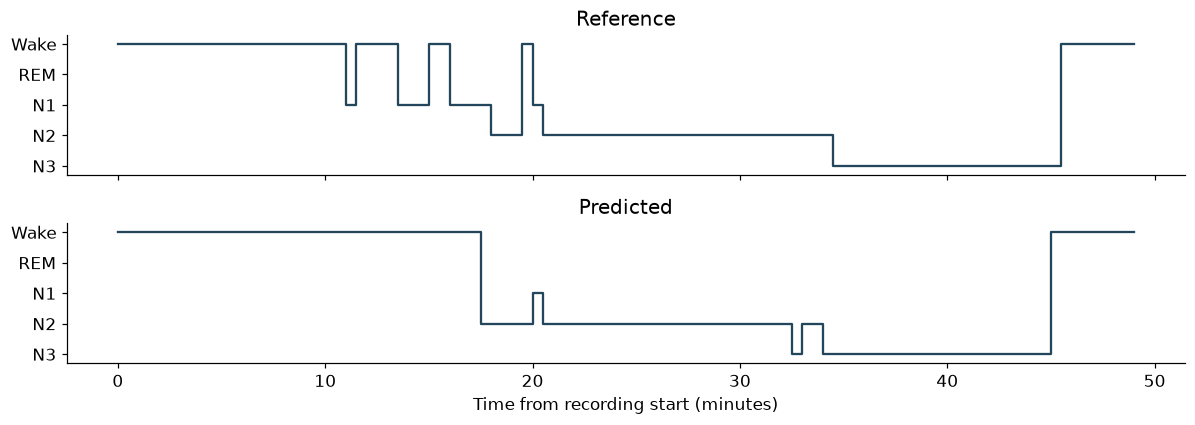

In [5]:
# Conventional vertical order: Wake at the top, N3 at the bottom.
positions = {"N3": 0, "N2": 1, "N1": 2, "REM": 3, "WAKE": 4}
edges_min = np.arange(len(reference) + 1) * 0.5
fig, axes = plt.subplots(2, 1, figsize=(11, 4), sharex=True)
for ax, labels, title in zip(axes, [reference, predicted], ["Reference", "Predicted"]):
    y = [positions[label] for label in labels]
    ax.step(edges_min, [*y, y[-1]], where="post", color="#24465D")
    ax.set(yticks=range(5), yticklabels=["N3", "N2", "N1", "REM", "Wake"],
           ylim=(-0.3, 4.3), title=title)
axes[-1].set_xlabel("Time from recording start (minutes)")
fig.tight_layout()
plt.show()

## 4. Try it: choose a review cutoff · 3 minutes

`Max_probability` is the model's highest predicted stage probability. It
describes model confidence; it does not establish that the label is correct.

**Predict first:** if we increase the review cutoff from **0.6 to 0.8**, will
more or fewer epochs be flagged? Does changing this cutoff change the stages?

Run the helper cell, then change only `review_cutoff` in the short cell below.

In [6]:
stage_table = pd.DataFrame({
    "Epoch": np.arange(len(reference)), "Start_min": np.arange(len(reference)) * 0.5,
    "Reference": reference, "Predicted": predicted, "Max_probability": confidence,
})

def review_predictions(cutoff=0.6):
    table = stage_table.copy()
    table["Flag_for_review"] = table["Max_probability"] < cutoff
    fig, ax = plt.subplots(figsize=(11, 2.7))
    ax.plot(table.Start_min, table.Max_probability, color="#24465D", lw=1)
    flagged = table.Flag_for_review
    ax.scatter(table.loc[flagged, "Start_min"], table.loc[flagged, "Max_probability"],
               color="#CA6B32", label="Flagged for review", zorder=3)
    ax.axhline(cutoff, color="#CA6B32", ls="--", label=f"Review cutoff = {cutoff:.1f}")
    ax.set(xlabel="Time (minutes)", ylabel="Max probability", ylim=(0, 1.03))
    ax.legend(loc="lower right")
    plt.show()
    print(f"{int(flagged.sum())} of {len(table)} epochs flagged; stage predictions unchanged.")
    display(table.loc[flagged].round(3))
    return table

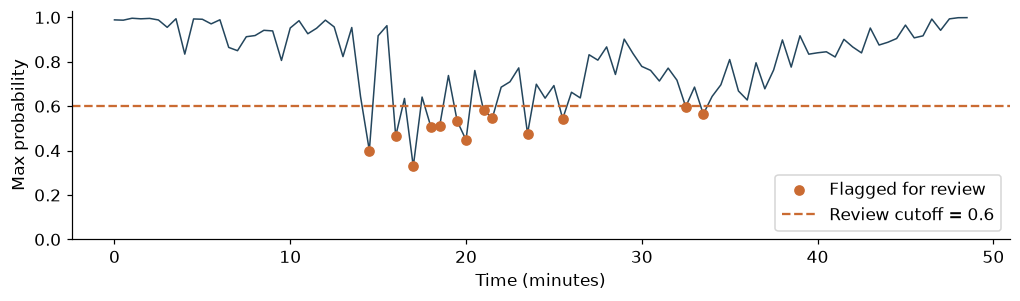

13 of 98 epochs flagged; stage predictions unchanged.


,Epoch,Start_min,Reference,Predicted,Max_probability,Flag_for_review
29,29,14.5,N1,WAKE,0.400,True
32,32,16.0,N1,WAKE,0.465,True
34,34,17.0,N1,WAKE,0.328,True
36,36,18.0,N2,N2,0.507,True
37,37,18.5,N2,N2,0.510,True
39,39,19.5,WAKE,N2,0.532,True
40,40,20.0,N1,N1,0.448,True
42,42,21.0,N2,N2,0.581,True
43,43,21.5,N2,N2,0.547,True
47,47,23.5,N2,N2,0.476,True


In [7]:
review_cutoff = 0.6  # CHANGE ME to 0.8, then rerun just this cell.
review_table = review_predictions(review_cutoff)

**Discuss with a neighbour:** which claim can you support from the figure?
Which information would you inspect before accepting an uncertain epoch?

## 5. Inspect one 30-second epoch

The default is the least-confident epoch. Three traces show the information
available to the model. A high-confidence disagreement also deserves review.

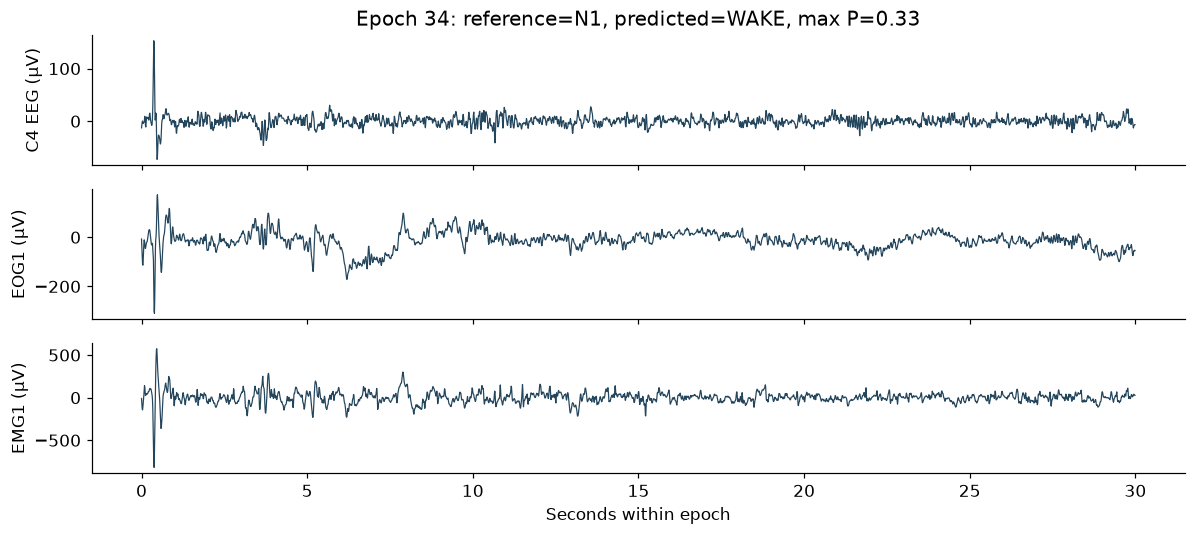

,WAKE,N1,N2,N3,REM
Epoch,,,,,
34,0.328,0.277,0.297,0.003,0.096


In [8]:
def inspect_epoch(epoch):
    epoch = int(epoch)
    start, stop = int(epoch * 30 * sf), int((epoch + 1) * 30 * sf)
    signals = raw.get_data(picks=["C4", "EOG1", "EMG1"], start=start, stop=stop,
                           units={"eeg": "uV", "eog": "uV", "emg": "uV"})
    time_s = np.arange(signals.shape[1]) / sf
    fig, axes = plt.subplots(3, 1, figsize=(11, 5), sharex=True)
    for ax, signal, label in zip(axes, signals, ["C4 EEG", "EOG1", "EMG1"]):
        ax.plot(time_s, signal, color="#24465D", lw=0.8)
        ax.set_ylabel(label + " (µV)")
    axes[0].set_title(f"Epoch {epoch}: reference={reference[epoch]}, predicted={predicted[epoch]}, max P={confidence[epoch]:.2f}")
    axes[-1].set_xlabel("Seconds within epoch")
    fig.tight_layout()
    plt.show()
    display(proba.iloc[[epoch]].round(3))

lowest_confidence_epoch = int(np.argmin(confidence))
inspect_epoch(lowest_confidence_epoch)

**Interactive browser:** choose an epoch and click **Inspect epoch**.
If the widget is unavailable, edit and run `inspect_epoch(0)` instead.

In [9]:
epoch_slider = widgets.IntSlider(value=lowest_confidence_epoch, min=0, max=len(reference)-1,
                                 description="Epoch", continuous_update=False)
inspect_button = widgets.Button(description="Inspect epoch")
epoch_output = widgets.Output()
def on_epoch_click(_):
    with epoch_output:
        epoch_output.clear_output(wait=True)
        inspect_epoch(epoch_slider.value)
inspect_button.on_click(on_epoch_click)
display(widgets.VBox([widgets.HBox([epoch_slider, inspect_button]), epoch_output]))

## 6. Keep the reference and predictions distinct

This export contains the **predicted** stages, reference stages and the model
probabilities aligned to the same epochs. A confidence column belongs with
the prediction that produced it.

In [10]:
export_table = stage_table.join(proba.reset_index(drop=True).add_prefix("P_"))
export_table.to_csv(OUT / "staging_predictions.csv", index=False)
(OUT / "analysis_choices.json").write_text(json.dumps({
    "source": "YASA notebook 14", "sample": "sub-02_mne_raw.fif",
    "epoch_seconds": 30, "inputs": ["C4", "EOG1", "EMG1"],
    "demographics_supplied": False, "reference_has_REM": bool(np.any(reference == "REM")),
    "agreement_percent": float(agreement),
}, indent=2))
print("Saved:", OUT / "staging_predictions.csv")

Saved: <repository>/outputs/three_notebook_workshop/14_automatic_sleep_staging/staging_predictions.csv


## Take-home messages

* Stages describe epochs; spindle and slow-wave detectors describe shorter events.
* Review confidence and disagreements alongside the original signals.
* A cutoff for review changes the review list, while the model predictions stay fixed.

## Optional extension · after the core lesson

What changes if only EEG is available? The next cell reruns the classifier
without EOG/EMG. Compare rather than assume that either model must win on this
single nap. This does not validate EEG-only staging on another population.

In [11]:
hyp_pred_eeg = yasa.SleepStaging(raw, eeg_name="C4").predict()
comparison = pd.DataFrame({
    "Reference": reference, "EEG_EOG_EMG": predicted,
    "EEG_only": hyp_pred_eeg.hypno.to_numpy(),
})
display(pd.Series({
    "EEG + EOG + EMG agreement (%)": agreement,
    "EEG-only agreement (%)": 100 * np.mean(comparison.Reference == comparison.EEG_only),
}).round(1))

<repository>/.venv/lib/python3.12/site-packages/sklearn/base.py:525: InconsistentVersionWarning: Trying to unpickle estimator LabelEncoder from version 0.24.2 when using version 1.9.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(


EEG + EOG + EMG agreement (%)    87.8
EEG-only agreement (%)           67.3
dtype: float64

[Staging documentation and review requirements](https://yasa-sleep.org/generated/yasa.SleepStaging.html)

**Next:** [01 · Spindle detection](02_YASA_spindles_detection.ipynb).

## Sources and attribution

YASA: Raphael Vallat, Remington Mallett and contributors; BSD 3-Clause licence
(`YASA_LICENSE.txt` in the workshop folder). Sample data: [YASA dataset v1](https://zenodo.org/records/14564285).

The short explanations, worked examples and learner prompts are inspired by
[Neurohackademy's public Python teaching notebook](https://github.com/neurohackademy/introduction-to-python/blob/master/introduction-to-python.ipynb).
The learning objectives, timing and exercises here are adaptations for this sleep
workshop, with no claim of an official Neurohackademy template or affiliation.